<a href="https://colab.research.google.com/github/heidiwms/project_template/blob/main/final_project_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Correlation of Fatalities from Cardiac Arrest with Prehospital Factors

**Team members:** Nithya Gopal, Jacob Khaykin, Heidi Williams

**Repository:** [URL of your team's fork]

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [12]:
import os

%cd /content/drive/MyDrive

repo_url = "https://github.com/heidiwms/project_template.git"
!git clone {repo_url}

/content/drive/MyDrive
Cloning into 'project_template'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 40 (delta 5), reused 30 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 71.71 KiB | 5.12 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import os
%cd /content/drive/MyDrive/project_template/data

from pathlib import Path
import pandas as pd
DATA_DIR = Path(".")
assert DATA_DIR.is_dir(), "The data directory is missing."

sas_file = DATA_DIR / "cardiacarrestpud_1to1.sas7bdat"
assert sas_file.exists(), f"{sas_file.name} is missing in {DATA_DIR.absolute()}"

/content/drive/MyDrive/project_template/data


## Load data

In [21]:
!apt-get update && apt-get install -y git-lfs
!git lfs install
!git lfs pull

import pandas as pd
df = pd.read_sas(DATA_DIR / "cardiacarrestpud_1to1.sas7bdat", encoding="utf-8")
df.head()

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,110 kB]
Get:

,PcrKey,eArrest_01,eArrest_02,eArrest_07,eArrest_11,eArrest_16,eArrest_18,eDispatch_01,eDispatch_02,eDisposition_16,eDisposition_19,eDisposition_21,ePatient_15,ePatient_16,eResponse_07,eScene_01,eScene_09,eSituation_02,eSituation_13
0,225614118.0,3001003,3002001,3007001,3011001,3016005,3018003,2301013,7701003,7701001,7701001,7701001,88.0,2516009,2207009,9923003,Y92.12,9922001,7701003
1,225614544.0,3001003,3002001,3007001,3011011,3016009,3018003,2301019,7701003,7701001,7701001,7701001,77.0,2516009,2207009,9923003,Y92.0,9922001,7701003
2,225614812.0,3001003,3002001,7701001,7701001,7701001,7701001,2301013,2302001,4216005,4219003,4221003,65.0,2516009,2207003,9923003,Y92.01,9922001,2813003
3,225614990.0,3001003,3002001,3007001,3011005,3016003,3018003,2301019,2302001,7701001,4219001,7701001,36.0,2516009,2207003,9923003,Y92.0,9922001,2813001
4,225615289.0,3001003,3002001,3007001,3011001,7701003,3018001,2301019,7701003,4216005,4219001,4221003,41.0,2516009,2207003,9923001,Y92.00,9922001,2813001


## Prepare data

In [28]:
# cleaning
# make sure patients only appear once
df = df.drop_duplicates("PcrKey").copy()

# Added by Nithya: Filter out special NEMSIS code values like 7701001 (Not Applicable) or 7701003 (Not Recorded) from age before computing
valid_age_mask = (df["ePatient_15"] < 120) & (df["ePatient_15"] >= 0)
clean_age = df["ePatient_15"].where(valid_age_mask)

# make age into "years" for ease of use
units = {"2516001": 365.25, "2516003": 8766, "2516005": 525960, "2516007": 12, "2516009": 1}
df["age_years"] = clean_age / df["ePatient_16"].map(units)

# note if EMS was there for the arrest
df["arrest_before_ems"] = (df["eArrest_01"] == "3001003").astype(int)

# did the patient get a pulse back (1 = yes, 0 = no)
df["rosc"] = df["eArrest_18"].map({"3018007": 1, "3018009": 1, "3018001": 0, "3018003": 0})

df.head()

,PcrKey,eArrest_01,eArrest_02,eArrest_07,eArrest_11,eArrest_16,eArrest_18,eDispatch_01,eDispatch_02,eDisposition_16,...,ePatient_15,ePatient_16,eResponse_07,eScene_01,eScene_09,eSituation_02,eSituation_13,age_years,arrest_before_ems,rosc
0,225614118.0,3001003,3002001,3007001,3011001,3016005,3018003,2301013,7701003,7701001,...,88.0,2516009,2207009,9923003,Y92.12,9922001,7701003,88.0,1,0.0
1,225614544.0,3001003,3002001,3007001,3011011,3016009,3018003,2301019,7701003,7701001,...,77.0,2516009,2207009,9923003,Y92.0,9922001,7701003,77.0,1,0.0
2,225614812.0,3001003,3002001,7701001,7701001,7701001,7701001,2301013,2302001,4216005,...,65.0,2516009,2207003,9923003,Y92.01,9922001,2813003,65.0,1,NaN
3,225614990.0,3001003,3002001,3007001,3011005,3016003,3018003,2301019,2302001,7701001,...,36.0,2516009,2207003,9923003,Y92.0,9922001,2813001,36.0,1,0.0
4,225615289.0,3001003,3002001,3007001,3011001,7701003,3018001,2301019,7701003,4216005,...,41.0,2516009,2207003,9923001,Y92.00,9922001,2813001,41.0,1,0.0


## Explore data

In [29]:
# Summary statistics for patient age, arrest timing, ROSC (return of spontaneous circulation)
print("--- Summary Statistics for Age and Key Indicators ---")
display(df[['age_years', 'arrest_before_ems', 'rosc']].describe())

print("\n--- ROSC Value Counts (1 = Yes, 0 = No) ---")
display(df['rosc'].value_counts(dropna=False))

--- Summary Statistics for Age and Key Indicators ---


,age_years,arrest_before_ems,rosc
count,272473.000000,274531.000000,202751.000000
mean,66.597013,0.912797,0.195230
std,17.010780,0.282133,0.396378
min,0.000002,0.000000,0.000000
25%,57.000000,1.000000,0.000000
50%,68.000000,1.000000,0.000000
75%,79.000000,1.000000,0.000000
max,119.000000,1.000000,1.000000



--- ROSC Value Counts (1 = Yes, 0 = No) ---


,count
rosc,
0.0,163168
NaN,71780
1.0,39583


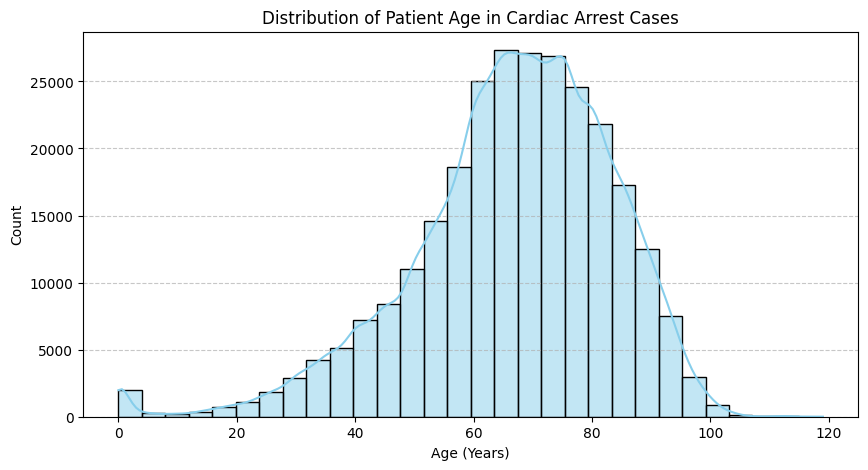

In [32]:
# Visualize patient age distribution (histogram)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df['age_years'].dropna(), bins=30, kde=True, color='skyblue')
plt.title('Distribution of Patient Age in Cardiac Arrest Cases')
plt.xlabel('Age (Years)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

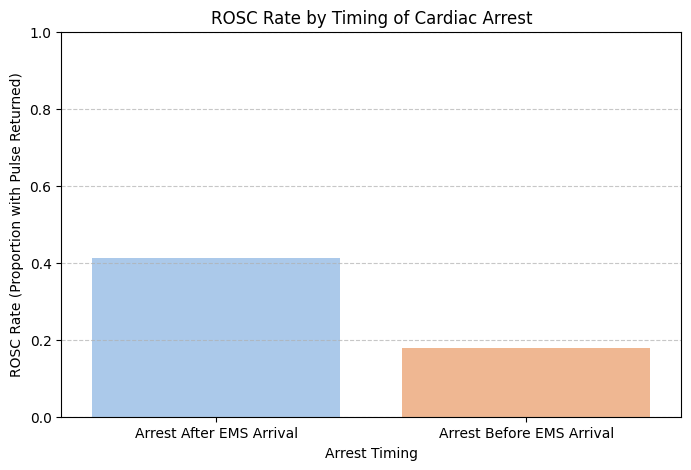

In [33]:
# Visualize ROSC rates by whether arrest occurred before EMS arrival (bar chart)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='arrest_before_ems', y='rosc', errorbar=None, hue='arrest_before_ems', legend=False, palette='pastel')
plt.title('ROSC Rate by Timing of Cardiac Arrest')
plt.xticks([0, 1], ['Arrest After EMS Arrival', 'Arrest Before EMS Arrival'])
plt.xlabel('Arrest Timing')
plt.ylabel('ROSC Rate (Proportion with Pulse Returned)')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Build models

In [ ]:
# Train baseline and candidate models.

## Evaluate models

In [ ]:
# Compare models using the chosen evaluation measures.

## Final results

In [ ]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]